# RM6 · The 2D Fourier transform and images

**Part:** Math refresher · **Reading time:** ~25 min · **Pass 1 overview:** [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [RM4 Fourier properties](RM4_Fourier_Properties.ipynb), [RM5 Fourier pairs and sampling](RM5_Fourier_Pairs_and_Sampling.ipynb)

An MRI scanner does not measure pixels. It measures **k-space**: the 2D (or 3D) Fourier transform of the image,
one point or line at a time. To read k-space, you need a feel for what a single k-space point "looks like" in the image
(a stripe pattern), which parts of k-space carry contrast and which carry detail, and why the 2D transform can be done
one direction at a time. This notebook builds that intuition with pictures, using a phantom and a real MRI data set.

## Learning goals

1. Write the 2D FT and explain each k-space point as a **plane wave** (stripe pattern) with a direction and a wavelength.
2. Predict what the k-space centre and periphery contribute to an image, and what a single corrupted k-space point does.
3. Use **separability**: a 2D FFT is 1D FFTs along rows, then along columns — the basis of Cartesian MRI reconstruction.
4. State the **rotation** property and the relative importance of k-space **magnitude and phase**.

## Symbols used in this notebook

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $x,\ y$ | in-plane position | m | |
| $k_x,\ k_y$ | spatial frequencies (k-space coordinates) | m⁻¹ | in code often in cycles/FOV (dimensionless) |
| $\vec k=[k_x,k_y]^T$, $\vec r=[x,y]^T$ | k-space and position vectors | m⁻¹, m | |
| $\lvert\vec k\rvert$ | spatial frequency magnitude; stripe wavelength $=1/\lvert\vec k\rvert$ | m⁻¹ | |
| $f(x,y)$, $F(k_x,k_y)$ | an image and its 2D FT | a.u., a.u.·m² | |
| $m(\vec r)$, $M(\vec k)$ | MRI image and its k-space data ($M$ here is k-space, **not** magnetization) | a.u. | |
| $FOV$, $\Delta k=1/FOV$ | field of view, k-space spacing | m, m⁻¹ | 0.24 m ↔ 4.2 m⁻¹ |
| $N$ | matrix size | – | 128–256 |
| $\alpha$ | rotation angle | rad (or °) | |
| $R_\alpha$ | 2D rotation matrix by $\alpha$ | – | |
| $\lvert F\rvert$, $\angle F$ | magnitude and phase of k-space | a.u., rad | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

from scipy.io import loadmat
from scipy.ndimage import rotate

## 1. The 2D Fourier transform and its basis functions

$$F(k_x,k_y)=\iint f(x,y)\,e^{-i2\pi(k_xx+k_yy)}\,dx\,dy,\qquad f(x,y)=\iint F(k_x,k_y)\,e^{+i2\pi(k_xx+k_yy)}\,dk_x\,dk_y.$$

In words: the image is a weighted sum of 2D complex waves $e^{i2\pi\vec k\cdot\vec r}$; $F(\vec k)$ says how much of each wave is present (amplitude and phase).
Where: $x,y$ [m] position, $k_x,k_y$ [m⁻¹] spatial frequencies; in MRI $f=m$ (the image) and $F=M$ (k-space).

Each **basis function** $e^{i2\pi(k_xx+k_yy)}$ is constant along lines perpendicular to $\vec k$ — a **plane wave**, which looks like a set of **stripes**:

- the stripes run **perpendicular** to the vector $\vec k$;
- their wavelength (distance between bright stripes) is $1/|\vec k|$;
- $\vec k=0$ is a constant (the average brightness).

On an $N\times N$ grid with k measured in **cycles per FOV**, the point $(k_x,k_y)=(3,0)$ is a pattern with 3 stripes across the FOV. Below, each panel is the real part of the inverse FFT of a k-space that is zero except at one point.

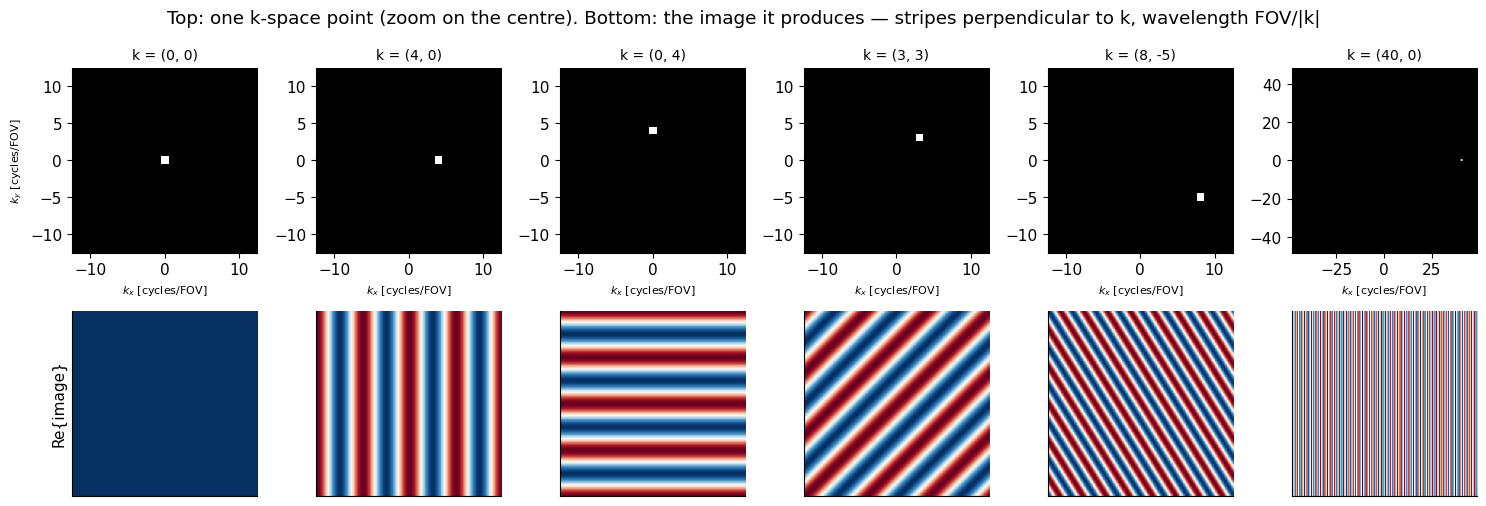

In [2]:
N = 128
points = [(0, 0), (4, 0), (0, 4), (3, 3), (8, -5), (40, 0)]     # (kx, ky) in cycles/FOV
fig, ax = plt.subplots(2, len(points), figsize=(15, 5.2))
for j, (kx, ky) in enumerate(points):
    K = np.zeros((N, N), complex)
    K[N // 2 + ky, N // 2 + kx] = 1.0                 # row index = ky, column index = kx
    img = mt.ifft2c(K)
    zoom = 12 if max(abs(kx), abs(ky)) <= 12 else 48     # half-width of the displayed k-space region
    crop = np.abs(K[N // 2 - zoom:N // 2 + zoom + 1, N // 2 - zoom:N // 2 + zoom + 1])
    ax[0, j].imshow(crop, cmap="gray", origin="lower", extent=[-zoom - 0.5, zoom + 0.5, -zoom - 0.5, zoom + 0.5])
    ax[0, j].set_title(f"k = ({kx}, {ky})", fontsize=10); ax[0, j].grid(False)
    ax[0, j].set_xlabel(r"$k_x$ [cycles/FOV]", fontsize=8)
    mt.show_image(img.real, ax=ax[1, j], cmap="RdBu_r")
ax[0, 0].set_ylabel(r"$k_y$ [cycles/FOV]", fontsize=8)
ax[1, 0].set_ylabel("Re{image}")
fig.suptitle("Top: one k-space point (zoom on the centre). Bottom: the image it produces — stripes perpendicular to k, wavelength FOV/|k|")
plt.tight_layout(); plt.show()

$(4,0)$ gives 4 vertical stripes, $(0,4)$ 4 horizontal ones, $(3,3)$ diagonal stripes, and $(40,0)$ very fine stripes — the "detail" frequencies. Every MRI image is a sum of such patterns.

> **⚠️ Common confusion — image display orientation:** `imshow` with the default `origin="upper"` puts row 0 at the top, so "+$k_y$" (higher row index) points *down* on an image display
> (the k-space panels above use `origin="lower"`). Radiological display conventions add another layer (patient left on image right). Always check axis directions before interpreting signs.

> **📐 Math note:** a *real* stripe pattern $\cos(2\pi\vec k\cdot\vec r)$ needs **two** k-space points, $+\vec k$ and $-\vec k$, each with weight 1/2 — the conjugate symmetry of real images ([RM4](RM4_Fourier_Properties.ipynb)). The single-point images above are complex; we show their real part.

### A single bad k-space point corrupts the whole image

Because each k-space point is a stripe pattern spanning the entire image, an error in **one** sample (e.g. a spark from a loose connection or static discharge in the bore) adds stripes
everywhere. This is the **spike** or **"herringbone"** artifact ([I2 Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb)).

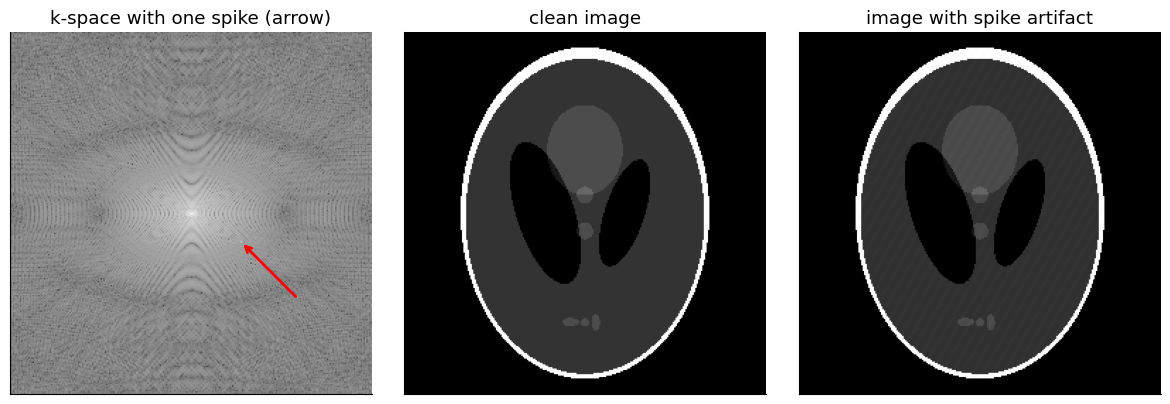

In [3]:
img = mt.shepp_logan(256)
K = mt.fft2c(img)
K_bad = K.copy()
K_bad[128 + 20, 128 + 35] += 0.05 * np.abs(K).max()    # one corrupted sample at k = (35, 20) cycles/FOV
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
mt.show_kspace(K_bad, ax=ax[0], title="k-space with one spike (arrow)")
ax[0].annotate("", xy=(128 + 35, 128 + 20), xytext=(128 + 75, 128 + 60), arrowprops=dict(arrowstyle="->", color="r", lw=2))
mt.show_image(mt.ifft2c(K), ax=ax[1], title="clean image")
mt.show_image(mt.ifft2c(K_bad), ax=ax[2], title="image with spike artifact")
plt.tight_layout(); plt.show()

A single wrong number out of 65 536 overlays diagonal stripes on the whole image.

## 2. Centre = contrast, periphery = edges

Natural images (and MRI images) have most of their energy at low spatial frequencies ([RM4](RM4_Fourier_Properties.ipynb), Parseval): large uniform regions are built from
long-wavelength waves near $\vec k=0$; sharp edges and fine detail need short-wavelength waves far from the centre. Masking k-space shows this directly.

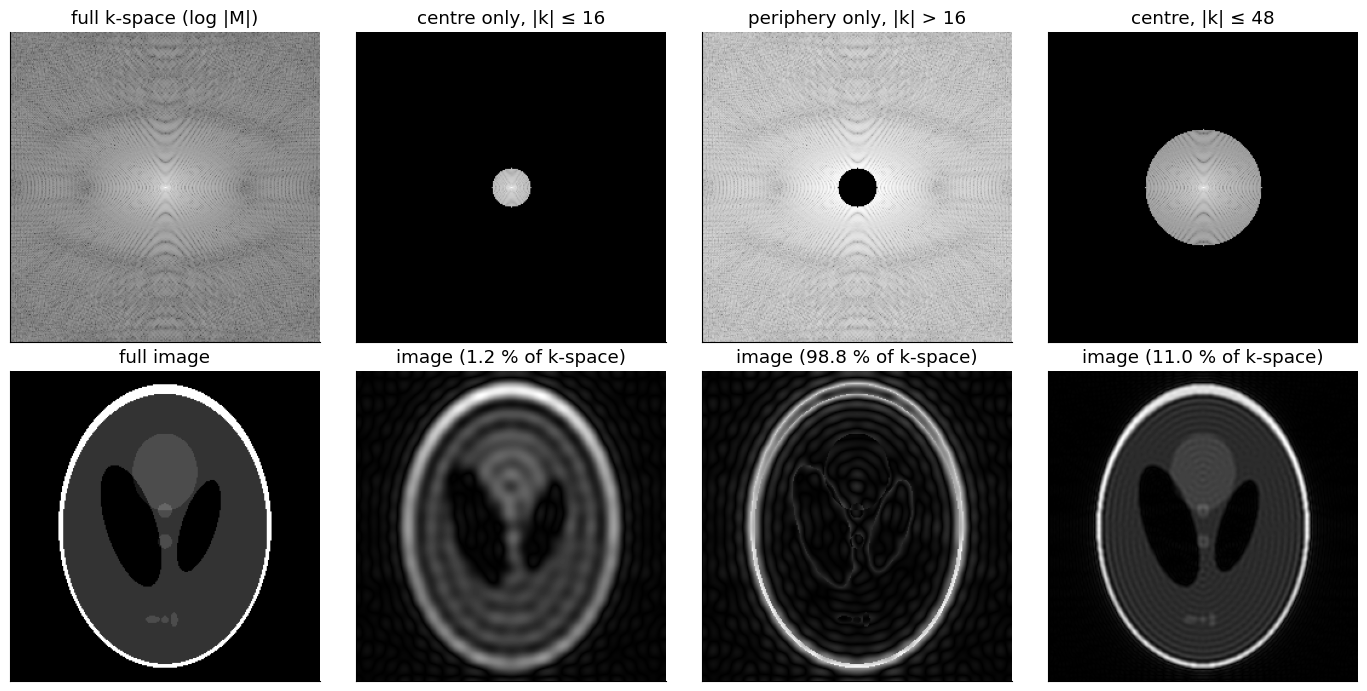

In [4]:
img = mt.shepp_logan(256)
K = mt.fft2c(img)
kx, ky = np.meshgrid(np.arange(256) - 128, np.arange(256) - 128)
kr = np.hypot(kx, ky)                                   # |k| in cycles/FOV
fig, ax = plt.subplots(2, 4, figsize=(14, 7))
mt.show_kspace(K, ax=ax[0, 0], title="full k-space (log |M|)")
mt.show_image(img, ax=ax[1, 0], title="full image")
for j, (mask, name) in enumerate([(kr <= 16, "centre only, |k| ≤ 16"), (kr > 16, "periphery only, |k| > 16"), (kr <= 48, "centre, |k| ≤ 48")]):
    mt.show_kspace(K * mask, ax=ax[0, j + 1], title=name)
    rec = mt.ifft2c(K * mask)
    mt.show_image(np.abs(rec), ax=ax[1, j + 1], title=f"image ({np.mean(mask)*100:.1f} % of k-space)")
plt.tight_layout(); plt.show()

The central 1.2 % of k-space already gives the right overall brightness and contrast (blurry); the periphery alone gives only edges; with $|k|\le48$ the image is almost indistinguishable from the original apart from slight ringing.

**MRI consequences:**

- Image **contrast** (T1/T2 weighting) is determined by when the *centre* of k-space is acquired — e.g. the "effective TE" of a fast spin echo train ([H2 Fast imaging](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb)).
- **Resolution** is determined by how far out you sample ($\delta=1/(2k_{max})$, [G1](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb)).
- **Motion** during the acquisition of the centre is far more damaging than during the periphery; many accelerated methods sample the centre densely and the periphery sparsely ([H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb)).

The same on a real MRI data set (T1-weighted spin echo, sagittal head, 256 × 256 k-space from the original book):

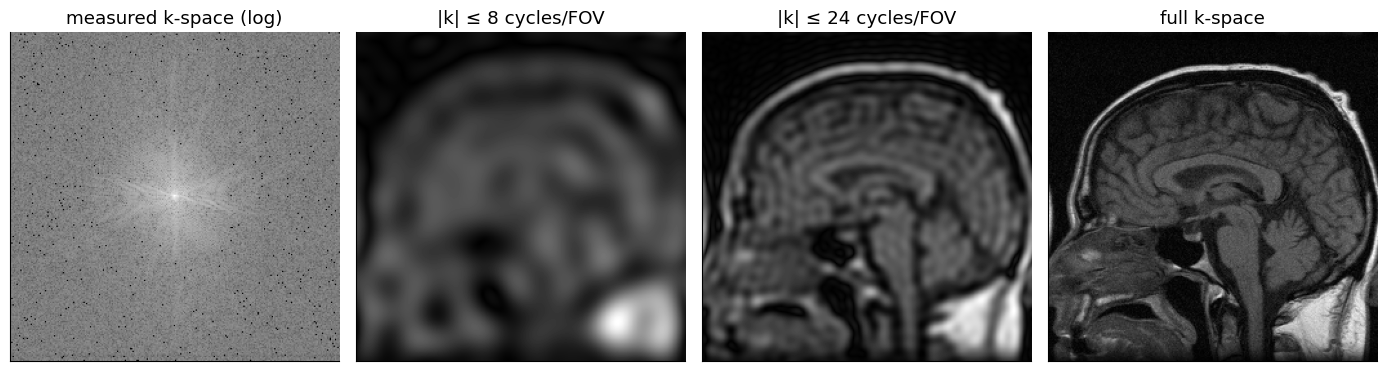

In [5]:
Kd = loadmat("../data/se_t1_sag_data.mat")["data"]      # measured k-space (complex)
img_d = mt.ifft2c(Kd)
ky_, kx_ = np.meshgrid(np.arange(256) - 128, np.arange(256) - 128, indexing="ij")
kr_d = np.hypot(kx_, ky_)
fig, ax = plt.subplots(1, 4, figsize=(14, 3.8))
mt.show_kspace(Kd, ax=ax[0], title="measured k-space (log)")
for a_, r in zip(ax[1:], [8, 24, np.inf]):
    mt.show_image(mt.ifft2c(Kd * (kr_d <= r)), ax=a_, title=f"|k| ≤ {r} cycles/FOV" if np.isfinite(r) else "full k-space")
plt.tight_layout(); plt.show()

With only $|k|\le8$ you can already tell it is a sagittal head; anatomy appears at 24; the full data set gives the sharp image.

## 3. Separability: 2D FFT = 1D FFTs along each axis

The 2D kernel factorizes, $e^{-i2\pi(k_xx+k_yy)}=e^{-i2\pi k_xx}\,e^{-i2\pi k_yy}$, so

$$F(k_x,k_y)=\int\left[\int f(x,y)\,e^{-i2\pi k_xx}\,dx\right]e^{-i2\pi k_yy}\,dy.$$

In words: first transform every row along $x$, then every column of the result along $y$ (or the other order). Where: the inner bracket is a 1D FT for each fixed $y$.
If additionally $f(x,y)=f_x(x)f_y(y)$ is a product, then $F=F_x(k_x)F_y(k_y)$ (e.g. a rectangle → product of two sincs).

**MRI:** in Cartesian imaging one k-space direction is the readout (frequency encoding, $k_x$) and the other is phase encoding ($k_y$). Reconstruction can be done one axis at a time; after the 1D inverse FFT along the readout only,
the data are in **hybrid space** $(x,k_y)$, where e.g. readout-direction processing (removing oversampling, per-line corrections) is done ([F3 Image reconstruction](../pass2_deep_dive/F3_Image_Reconstruction.ipynb)).

1D along rows, then columns == 2D IFFT: True


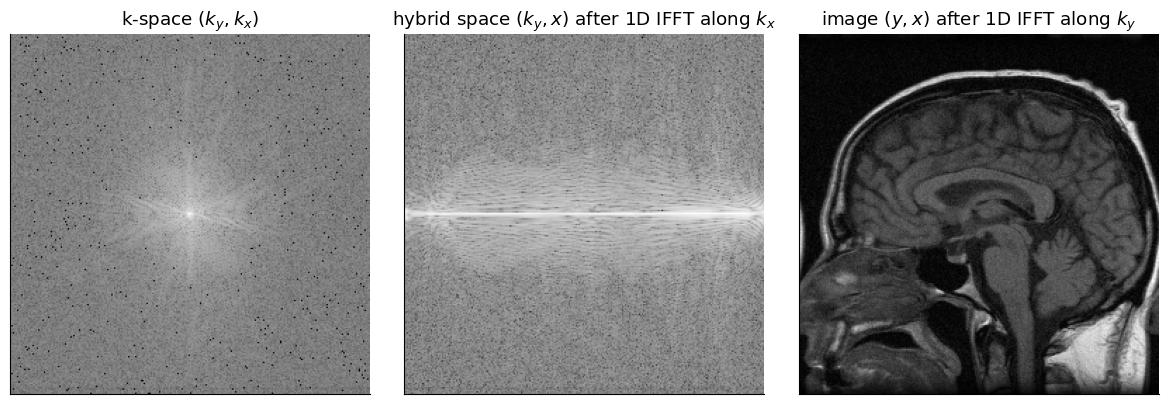

In [6]:
rows_then_cols = mt.ifftc(mt.ifftc(Kd, axis=1), axis=0)    # 1D inverse FFT along kx (each row), then along ky
print("1D along rows, then columns == 2D IFFT:", np.allclose(rows_then_cols, mt.ifft2c(Kd)))
hybrid = mt.ifftc(Kd, axis=1)                              # (ky, x): 1D IFFT along the readout only
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
mt.show_kspace(Kd, ax=ax[0], title=r"k-space $(k_y, k_x)$")
mt.show_kspace(hybrid, ax=ax[1], title=r"hybrid space $(k_y, x)$ after 1D IFFT along $k_x$")
mt.show_image(rows_then_cols, ax=ax[2], title=r"image $(y, x)$ after 1D IFFT along $k_y$")
plt.tight_layout(); plt.show()

Two passes of 1D transforms give exactly the 2D result; the middle panel shows the intermediate hybrid space, in which each row is still a single phase-encoding step.

## 4. Rotation: rotate the image, rotate k-space

If $f$ is rotated by an angle $\alpha$, its 2D FT is rotated by the same angle:

$$f(R_\alpha^{-1}\vec r)\;\longleftrightarrow\;F(R_\alpha^{-1}\vec k).$$

In words: k-space turns with the object. Where: $R_\alpha$ = 2D rotation matrix by $\alpha$. (Proof: substitute $\vec r'=R_\alpha^{-1}\vec r$ and use $\vec k\cdot R_\alpha\vec r'=(R_\alpha^{-1}\vec k)\cdot\vec r'$, since $R_\alpha^{-1}=R_\alpha^T$.)

**MRI:** this is why oblique slices and rotated FOVs work simply by rotating the gradient directions, and why radial k-space spokes at different angles each carry a projection of the object at the corresponding angle
(projection-slice theorem, [J5 Advanced reconstruction](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb)).

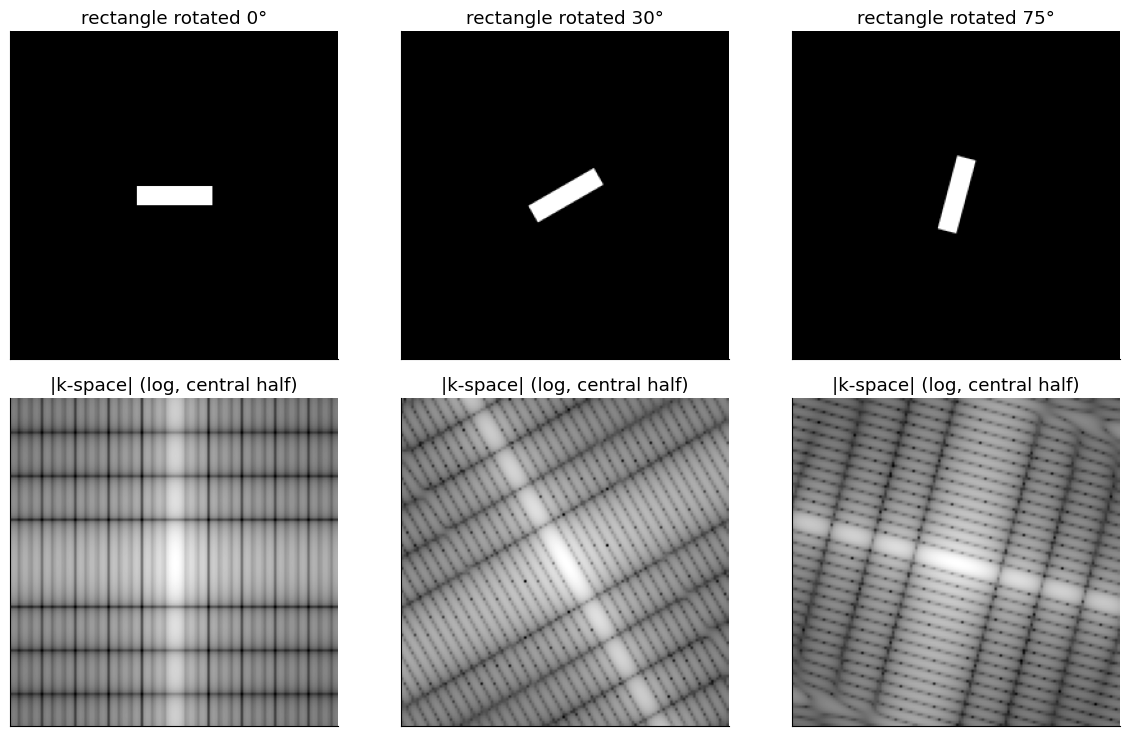

In [7]:
N = 256
yy, xx = np.mgrid[-N // 2:N // 2, -N // 2:N // 2]
rect_img = ((np.abs(xx) < 30) & (np.abs(yy) < 8)).astype(float)       # a 60 x 16 pixel rectangle
fig, ax = plt.subplots(2, 3, figsize=(12, 7.5))
for j, ang in enumerate([0, 30, 75]):
    im = rotate(rect_img, ang, reshape=False, order=1)
    Kr = mt.fft2c(im)
    mt.show_image(im, ax=ax[0, j], title=f"rectangle rotated {ang}°")
    mt.show_kspace(Kr[64:192, 64:192], ax=ax[1, j], title="|k-space| (log, central half)")
plt.tight_layout(); plt.show()

The k-space of the rectangle is a product of two sincs (separability), long along the rectangle's *short* axis (scaling); rotating the rectangle rotates this pattern by the same angle.

## 5. Magnitude vs phase of k-space: which carries the structure?

Swap the k-space **phase** of two images while keeping each one's **magnitude**. Which image do you see?

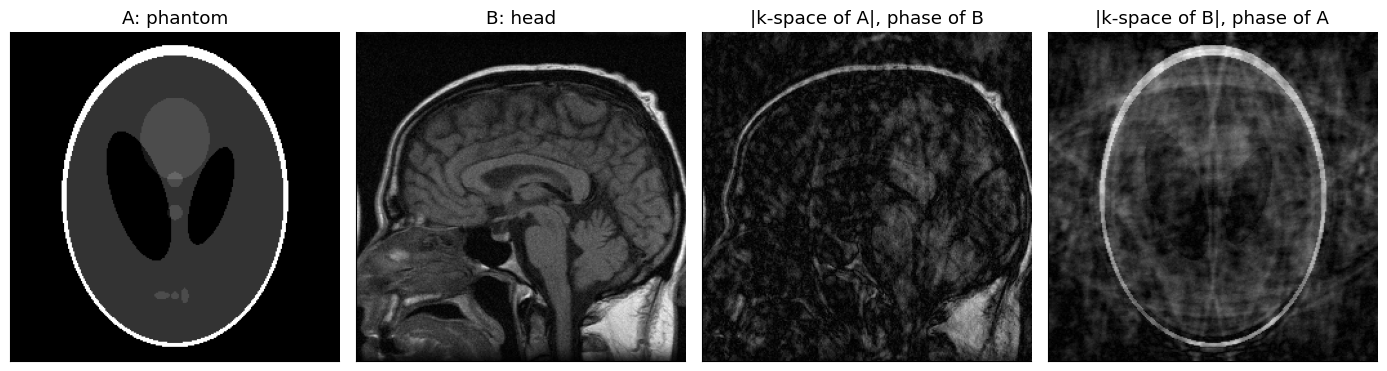

In [8]:
A = mt.shepp_logan(256)
B = np.abs(img_d) / np.abs(img_d).max()                 # the real head image, scaled to [0, 1]
KA, KB = mt.fft2c(A), mt.fft2c(B)
magA_phaseB = np.abs(KA) * np.exp(1j * np.angle(KB))
magB_phaseA = np.abs(KB) * np.exp(1j * np.angle(KA))
fig, ax = plt.subplots(1, 4, figsize=(14, 3.8))
mt.show_image(A, ax=ax[0], title="A: phantom")
mt.show_image(B, ax=ax[1], title="B: head")
mt.show_image(mt.ifft2c(magA_phaseB), ax=ax[2], title="|k-space of A|, phase of B")
mt.show_image(mt.ifft2c(magB_phaseA), ax=ax[3], title="|k-space of B|, phase of A")
plt.tight_layout(); plt.show()

Each hybrid looks like the image whose **phase** it carries: the k-space phase holds *where* the edges are (shift theorem: position ↔ phase), while the magnitude mostly holds the overall energy distribution over spatial frequencies,
which is similar for most images (large at the centre, falling off outwards).

> **⚠️ Common confusion:** do not confuse **k-space phase** (this section: needed to place structures correctly; you can never discard it) with **image phase** $\angle m(\vec r)$ (the phase of each pixel's $M_{xy}$,
> which reflects off-resonance, flow, coil sensitivity, and is often discarded by displaying $|m|$).

## Where this shows up in MRI

| Idea | Where it is used |
|---|---|
| k-space as the 2D FT of the image; one sample per encoding step | [F2 K-space](../pass2_deep_dive/F2_K-space.ipynb), [F1 Spatial encoding](../pass2_deep_dive/F1_Spatial_Encoding.ipynb) |
| separability, hybrid space, Cartesian recon | [F3 Image reconstruction](../pass2_deep_dive/F3_Image_Reconstruction.ipynb), [H1 Volumetric imaging](../pass2_deep_dive/H1_Volumetric_Imaging.ipynb) (3D = three 1D FFTs) |
| centre = contrast, periphery = resolution | [G1 FOV and resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb), [H2 Fast imaging sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb), [H3 Accelerated imaging](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb) |
| single k-space errors → stripes; PSF in 2D | [I2 Artifacts](../pass2_deep_dive/I2_Artifacts.ipynb), [I1 PSF analysis](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb), [G3 Cartesian image characteristics](../pass2_deep_dive/G3_Cartesian_Image_Characteristics.ipynb) |
| rotation, radial sampling | [J5 Advanced reconstruction](../pass2_deep_dive/J5_Advanced_Image_Reconstruction.ipynb), [J1 Excitation k-space](../pass2_deep_dive/J1_Excitation_K-space.ipynb) |

Compact formula sheet: [MRI math concepts](../reference/MRI_Math_Concepts.ipynb).

## Key takeaways

- Each k-space point $\vec k$ is a plane wave (stripes) perpendicular to $\vec k$ with wavelength $1/|\vec k|$; an image is the sum of all of them weighted by $M(\vec k)$.
- One corrupted k-space sample puts stripes over the entire image (spike/herringbone artifact).
- The k-space centre sets brightness and contrast; the periphery sets edges and fine detail (resolution).
- The 2D FFT is separable: 1D FFTs along rows, then columns; intermediate "hybrid space" is used in Cartesian reconstruction.
- Rotating an object rotates its k-space by the same angle.
- The k-space phase encodes where structures are and cannot be discarded; the image phase is a different quantity.

## Check your understanding

1. On a 24 cm FOV, which k-space point (in m⁻¹) produces horizontal stripes 6 mm apart?
<details><summary>Answer</summary>

Horizontal stripes vary along $y$, so $\vec k=(0,k_y)$ with $|k_y|=1/(6\text{ mm})\approx167$ m⁻¹, i.e. $167\times0.24=40$ cycles/FOV.

</details>

2. A FSE sequence acquires the k-space centre at the 8th echo (echo spacing 10 ms). Roughly what TE determines the contrast?
<details><summary>Answer</summary>

The effective TE ≈ 80 ms, because the centre of k-space (low spatial frequencies) dominates image brightness and contrast.

</details>

3. Why can a 2D FFT of a 256 × 256 image be computed as 512 1D FFTs of length 256?
<details><summary>Answer</summary>

The 2D kernel factorizes into an $x$ part and a $y$ part (separability): 256 FFTs along the rows, then 256 along the columns.

</details>

4. You keep the k-space magnitude of image A but replace its phase with zeros. What will the reconstruction look like?
<details><summary>Answer</summary>

Not like A: all waves now have zero phase, so they all have a crest at the image centre. The result is a point-symmetric pattern concentrated around the image centre; A's edges are no longer at their positions.

</details>

---
*New refresher written for this adaptation of P. Larson, "Principles of MRI" (MIT License); uses the original book's T1-weighted sagittal data set. See references below.*
*References: R. N. Bracewell, *Fourier Analysis and Imaging* (Springer);
R. C. Gonzalez, R. E. Woods, *Digital Image Processing* (Pearson);
A. V. Oppenheim, J. S. Lim, "The importance of phase in signals", *Proc. IEEE* 69:529–541 (1981);
D. G. Nishimura, *Principles of Magnetic Resonance Imaging*.*